# ANNs Project — Model 2
## CLIP Image Encoder + LSTM/GRU Text Decoder

This notebook trains **Model 2** for the project.

**Goal:**

```text
Best frame image  →  generated short query/caption
```

We use:

```text
Frozen CLIP image encoder → image feature vector → LSTM/GRU decoder → generated text
```

Why this version:

- We avoid GPT-2 because it is a pretrained text generator/LLM-style model and it produced long story-like outputs.
- CLIP is used only as a **frozen image feature extractor**, not as the text generator.
- The trainable generation part is a course-related **RNN decoder**: LSTM and GRU.
- We compare LSTM and GRU to match the ANN course topics.

## 1. Install and import libraries

This cell installs/loads the needed libraries. In Google Colab, run this at the beginning of the notebook.

In [41]:
!pip -q install transformers nltk

import os
import re
import json
import random
import zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision.transforms as T
import matplotlib.pyplot as plt

from transformers import CLIPModel
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.10.0+cu128
CUDA available: True


## 2. Reproducibility and device setup

This cell fixes random seeds and selects GPU if available.

In [42]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

SEED = 42
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 3. Mount Google Drive and set project paths

Change `PROJECT_DIR` if your shared Drive folder has a different path.

Expected structure after unzipping:

```text
thumbnail_project/
├── processed/
│   ├── m2_train_pairs.jsonl
│   └── m2_split_indices.json
└── qvh_frames/
    ├── video_segment_1.jpg
    └── ...
```

In [43]:
from google.colab import drive

drive.mount('/content/drive')

# CHANGE THIS if your folder name/path is different.
PROJECT_DIR = "/content/drive/MyDrive/thumbnail_project"

PROCESSED_DIR = os.path.join(PROJECT_DIR, "processed")
FRAMES_DIR = os.path.join(PROJECT_DIR, "qvh_frames")
EXPORT_DIR = os.path.join(PROJECT_DIR, "exports", "model2_clip_lstm_gru")
os.makedirs(EXPORT_DIR, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("PROCESSED_DIR:", PROCESSED_DIR)
print("FRAMES_DIR:", FRAMES_DIR)
print("EXPORT_DIR:", EXPORT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR: /content/drive/MyDrive/thumbnail_project
PROCESSED_DIR: /content/drive/MyDrive/thumbnail_project/processed
FRAMES_DIR: /content/drive/MyDrive/thumbnail_project/qvh_frames
EXPORT_DIR: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru


## 4. Optional: unzip the uploaded project folders

Run this cell only if `processed/` or `qvh_frames/` are still zipped in your Drive folder.

Put the zip files inside `PROJECT_DIR`, then edit the zip file names if needed.

In [44]:
# Optional zip paths. Edit the names if your files have different names.
PROCESSED_ZIP = os.path.join(PROJECT_DIR, "processed-20260506T210550Z-3-001.zip")
FRAMES_ZIP = os.path.join(PROJECT_DIR, "qvh_frames-20260506T214845Z-3-001.zip")

# Unzip processed folder if needed.
if not os.path.exists(os.path.join(PROCESSED_DIR, "m2_train_pairs.jsonl")) and os.path.exists(PROCESSED_ZIP):
    print("Unzipping processed folder...")
    with zipfile.ZipFile(PROCESSED_ZIP, 'r') as z:
        z.extractall(PROJECT_DIR)

# Unzip frames folder if needed.
if (not os.path.exists(FRAMES_DIR) or len(os.listdir(FRAMES_DIR)) == 0) and os.path.exists(FRAMES_ZIP):
    print("Unzipping qvh_frames folder...")
    with zipfile.ZipFile(FRAMES_ZIP, 'r') as z:
        z.extractall(PROJECT_DIR)

print("processed exists:", os.path.exists(PROCESSED_DIR))
print("qvh_frames exists:", os.path.exists(FRAMES_DIR))
print("number of frame files:", len(os.listdir(FRAMES_DIR)) if os.path.exists(FRAMES_DIR) else 0)

processed exists: True
qvh_frames exists: True
number of frame files: 1595


## 5. Load the image-text pairs

The file `m2_train_pairs.jsonl` contains rows like:

```json
{"frame_path": ".../qvh_frames/example.jpg", "query": "A woman is walking outside."}
```

We use the frame as the input image and the query as the target text.

In [45]:
PAIRS_PATH = os.path.join(PROCESSED_DIR, "m2_train_pairs.jsonl")
SPLIT_PATH = os.path.join(PROCESSED_DIR, "m2_split_indices.json")

assert os.path.exists(PAIRS_PATH), f"Missing file: {PAIRS_PATH}"

pairs = []
with open(PAIRS_PATH, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            pairs.append(json.loads(line))

print("Total pairs:", len(pairs))
print("Example row:")
print(json.dumps(pairs[0], indent=2))

Total pairs: 1608
Example row:
{
  "qid": 1,
  "frame_path": "/content/drive/MyDrive/thumbnail_project/qvh_frames/Q2TqU-Oh7KQ_360.0_510.0.jpg",
  "query": "Woman wears a white top walking down the street.",
  "vid": "Q2TqU-Oh7KQ_360.0_510.0",
  "best_timestamp": 73,
  "mean_saliency": 3.667
}


## 6. Fix frame paths and remove missing images

The JSON file may contain old Google Drive paths. To make the notebook portable, we take the image filename and rebuild the path using `FRAMES_DIR`.

In [46]:
def resolve_frame_path(old_path):
    filename = os.path.basename(old_path)
    return os.path.join(FRAMES_DIR, filename)

clean_pairs = []
missing = []
for row in pairs:
    if row.get("frame_path") is None:
        missing.append(row)
        continue
    new_path = resolve_frame_path(row["frame_path"])
    if os.path.exists(new_path):
        new_row = dict(row)
        new_row["frame_path"] = new_path
        clean_pairs.append(new_row)
    else:
        missing.append(row)

pairs = clean_pairs
print("Usable pairs:", len(pairs))
print("Missing pairs:", len(missing))
print("Example fixed path:", pairs[0]["frame_path"])

Usable pairs: 1608
Missing pairs: 0
Example fixed path: /content/drive/MyDrive/thumbnail_project/qvh_frames/Q2TqU-Oh7KQ_360.0_510.0.jpg


## 7. Split into training and validation sets

We use the saved split file if it exists. Otherwise, we create a random 90/10 split.

In [47]:
if os.path.exists(SPLIT_PATH):
    with open(SPLIT_PATH, "r", encoding="utf-8") as f:
        split_info = json.load(f)
    train_qids = set(split_info.get("train_qids", []))
    val_qids = set(split_info.get("val_qids", []))
    train_pairs = [p for p in pairs if p.get("qid") in train_qids]
    val_pairs = [p for p in pairs if p.get("qid") in val_qids]
else:
    random.shuffle(pairs)
    split_idx = int(0.9 * len(pairs))
    train_pairs = pairs[:split_idx]
    val_pairs = pairs[split_idx:]

print("Train pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))

Train pairs: 1448
Validation pairs: 160


## 8. Text cleaning and vocabulary building

We create a small word vocabulary from the training queries only.

Special tokens:

- `<PAD>`: padding token
- `<SOS>`: start of sentence
- `<EOS>`: end of sentence
- `<UNK>`: unknown word

In [48]:
PAD_TOKEN = "<PAD>"
SOS_TOKEN = "<SOS>"
EOS_TOKEN = "<EOS>"
UNK_TOKEN = "<UNK>"

SPECIAL_TOKENS = [PAD_TOKEN, SOS_TOKEN, EOS_TOKEN, UNK_TOKEN]
PAD_IDX, SOS_IDX, EOS_IDX, UNK_IDX = 0, 1, 2, 3

MAX_LEN = 25      # includes <SOS> and <EOS>; good for short query-like captions
MIN_FREQ = 1      # use 1 because the dataset is small


def clean_caption(text):
    text = text.lower().strip()
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize(text):
    return clean_caption(text).split()

counter = Counter()
for row in train_pairs:
    counter.update(tokenize(row["query"]))

words = [w for w, c in counter.items() if c >= MIN_FREQ]
idx2word = SPECIAL_TOKENS + sorted(words)
word2idx = {w: i for i, w in enumerate(idx2word)}

VOCAB_SIZE = len(idx2word)
print("Vocab size:", VOCAB_SIZE)
print("Most common words:", counter.most_common(20))

lengths = [len(tokenize(row["query"])) for row in pairs]
print("Mean caption length:", np.mean(lengths))
print("95th percentile length:", np.percentile(lengths, 95))
print("Max caption length:", np.max(lengths))

Vocab size: 2457
Most common words: [('a', 1671), ('in', 598), ('the', 547), ('woman', 477), ('and', 359), ('is', 338), ('of', 314), ('man', 275), ('on', 259), ('her', 203), ('with', 201), ('to', 188), ('are', 140), ('at', 114), ('girl', 97), ('white', 96), ('talking', 94), ('black', 87), ('from', 85), ('top', 79)]
Mean caption length: 10.303482587064677
95th percentile length: 17.0
Max caption length: 34


## 9. Caption encoding and decoding helpers

The decoder learns to predict the next word. We encode every query as:

```text
<SOS> word1 word2 ... wordN <EOS> <PAD> ...
```

In [49]:
def encode_caption(text, max_len=MAX_LEN):
    tokens = tokenize(text)
    token_ids = [word2idx.get(tok, UNK_IDX) for tok in tokens]
    token_ids = token_ids[:max_len - 2]
    token_ids = [SOS_IDX] + token_ids + [EOS_IDX]
    if len(token_ids) < max_len:
        token_ids += [PAD_IDX] * (max_len - len(token_ids))
    return torch.tensor(token_ids, dtype=torch.long)


def decode_ids(ids):
    words = []
    for idx in ids:
        idx = int(idx)
        if idx == EOS_IDX:
            break
        if idx in [PAD_IDX, SOS_IDX]:
            continue
        words.append(idx2word[idx] if idx < len(idx2word) else UNK_TOKEN)
    return " ".join(words)

# quick test
sample_encoded = encode_caption(train_pairs[0]["query"])
print("Original:", train_pairs[0]["query"])
print("Encoded:", sample_encoded.tolist())
print("Decoded:", decode_ids(sample_encoded.tolist()))

Original: Woman wears a white top walking down the street.
Encoded: [1, 2419, 2375, 16, 2394, 2202, 2351, 655, 2167, 2049, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Decoded: woman wears a white top walking down the street


## 10. Image preprocessing and augmentation

CLIP expects images normalized with CLIP's mean and standard deviation.

For training, we use light augmentation to reduce overfitting:

- random resized crop
- slight brightness/contrast change
- slight blur
- small rotation

For future real thumbnails, avoid strong degradation. If thumbnails contain text, do not use horizontal flip because it flips written text.

In [50]:
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)

USE_HORIZONTAL_FLIP = False  # keep False if images may contain text overlays

train_transform_list = [
    T.RandomResizedCrop(224, scale=(0.85, 1.0)),
    T.RandomApply([T.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02)], p=0.5),
    T.RandomApply([T.GaussianBlur(kernel_size=3)], p=0.15),
    T.RandomRotation(degrees=5),
]

if USE_HORIZONTAL_FLIP:
    train_transform_list.append(T.RandomHorizontalFlip(p=0.2))

train_transform_list += [
    T.ToTensor(),
    T.Normalize(mean=CLIP_MEAN, std=CLIP_STD),
]

train_transform = T.Compose(train_transform_list)

val_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=CLIP_MEAN, std=CLIP_STD),
])

## 11. Dataset and DataLoader

Each item returns:

```text
image tensor, encoded caption, original query, image path
```

In [51]:
class ImageCaptionDataset(Dataset):
    def __init__(self, pairs, transform=None, max_len=MAX_LEN):
        self.pairs = pairs
        self.transform = transform
        self.max_len = max_len

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        row = self.pairs[idx]
        image = Image.open(row["frame_path"]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        caption = encode_caption(row["query"], self.max_len)
        return image, caption, row["query"], row["frame_path"]

BATCH_SIZE = 16
NUM_WORKERS = 2

train_dataset = ImageCaptionDataset(train_pairs, transform=train_transform)
val_dataset = ImageCaptionDataset(val_pairs, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 91
Validation batches: 10


## 12. Visual check of training images

This cell shows a few images after augmentation, with their target queries.

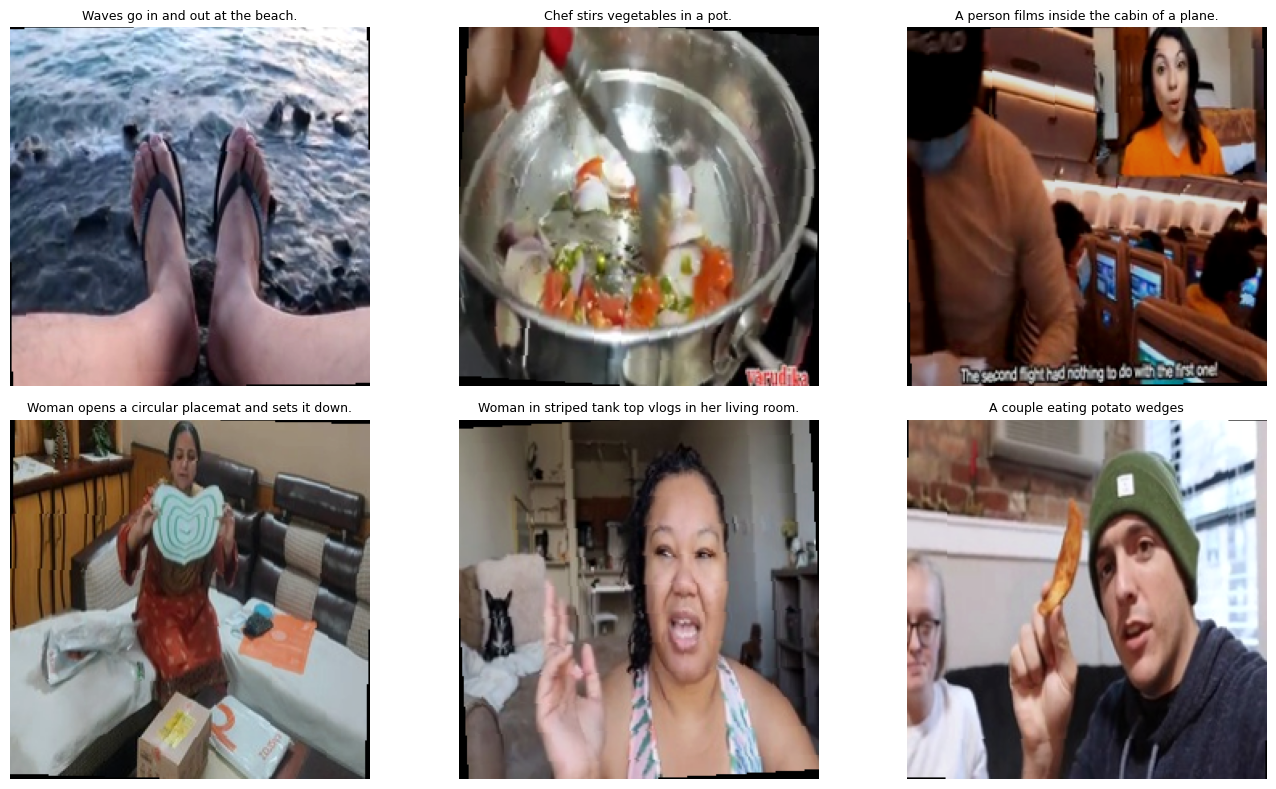

In [52]:
def denormalize_clip_image(tensor):
    mean = torch.tensor(CLIP_MEAN).view(3, 1, 1)
    std = torch.tensor(CLIP_STD).view(3, 1, 1)
    img = tensor.cpu() * std + mean
    return img.clamp(0, 1).permute(1, 2, 0).numpy()

images, captions, queries, paths = next(iter(train_loader))

plt.figure(figsize=(14, 8))
for i in range(min(6, images.size(0))):
    plt.subplot(2, 3, i + 1)
    plt.imshow(denormalize_clip_image(images[i]))
    plt.axis("off")
    plt.title(queries[i][:60], fontsize=9)
plt.tight_layout()
plt.show()

## 13. Load frozen CLIP image encoder

We use CLIP only to extract image features. Its weights are frozen.

The trainable part is only the LSTM/GRU decoder.

In [53]:
CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"

clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(device)
clip_model.eval()

for param in clip_model.parameters():
    param.requires_grad = False


def extract_clip_image_features(clip_model, pixel_values):
    """
    Extract CLIP image features safely.
    This handles different Transformers versions where the output format may differ.
    """
    with torch.no_grad():
        output = clip_model.get_image_features(pixel_values=pixel_values)

        # Normal case: output is already a tensor
        if torch.is_tensor(output):
            return output

        # Some versions/models return an object with image_embeds
        if hasattr(output, "image_embeds"):
            return output.image_embeds

        # Some versions return pooled visual output
        if hasattr(output, "pooler_output"):
            return output.pooler_output

        # Some versions return tuple/list
        if isinstance(output, (tuple, list)):
            return output[0]

        raise TypeError(f"Unexpected CLIP output type: {type(output)}")


with torch.no_grad():
    dummy = torch.zeros(1, 3, 224, 224).to(device)
    dummy_features = extract_clip_image_features(clip_model, dummy)
    IMAGE_FEATURE_DIM = dummy_features.shape[-1]

print("CLIP image feature dim:", IMAGE_FEATURE_DIM)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP image feature dim: 512


## 14. Decoder model: LSTM or GRU

The image feature initializes the hidden state of the decoder.

During training:

```text
caption input  = <SOS> word1 word2 ...
target output  = word1 word2 ... <EOS>
```

In [54]:
class CaptionDecoder(nn.Module):
    def __init__(self, vocab_size, image_feature_dim=512, embed_dim=256, hidden_dim=256,
                 decoder_type="lstm", dropout=0.3, num_layers=1):
        super().__init__()
        assert decoder_type in ["lstm", "gru"]
        self.decoder_type = decoder_type
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.dropout = nn.Dropout(dropout)

        self.feature_to_h = nn.Linear(image_feature_dim, hidden_dim * num_layers)
        if decoder_type == "lstm":
            self.feature_to_c = nn.Linear(image_feature_dim, hidden_dim * num_layers)
            self.rnn = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        else:
            self.rnn = nn.GRU(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True)

        self.fc = nn.Linear(hidden_dim, vocab_size)

    def init_hidden(self, image_features):
        batch_size = image_features.size(0)
        h = torch.tanh(self.feature_to_h(image_features))
        h = h.view(batch_size, self.num_layers, self.hidden_dim).permute(1, 0, 2).contiguous()

        if self.decoder_type == "lstm":
            c = torch.tanh(self.feature_to_c(image_features))
            c = c.view(batch_size, self.num_layers, self.hidden_dim).permute(1, 0, 2).contiguous()
            return (h, c)
        else:
            return h

    def forward(self, image_features, caption_inputs):
        hidden = self.init_hidden(image_features)
        embedded = self.dropout(self.embedding(caption_inputs))
        outputs, hidden = self.rnn(embedded, hidden)
        outputs = self.dropout(outputs)
        logits = self.fc(outputs)
        return logits

## 15. Caption generation function

This function generates a caption word-by-word using greedy decoding.

In [55]:
@torch.no_grad()
def get_image_features(images):
    features = extract_clip_image_features(clip_model, images)
    features = features / features.norm(dim=-1, keepdim=True)
    return features

@torch.no_grad()
def generate_caption_from_tensor(image_tensor, decoder, max_len=MAX_LEN):
    decoder.eval()
    image_tensor = image_tensor.unsqueeze(0).to(device)
    image_features = get_image_features(image_tensor)

    current_token = torch.tensor([[SOS_IDX]], dtype=torch.long, device=device)
    hidden = decoder.init_hidden(image_features)
    generated_ids = []

    for _ in range(max_len - 1):
        embedded = decoder.embedding(current_token)
        output, hidden = decoder.rnn(embedded, hidden)
        logits = decoder.fc(output[:, -1, :])
        next_token = torch.argmax(logits, dim=-1)
        next_id = int(next_token.item())

        if next_id == EOS_IDX:
            break
        if next_id not in [PAD_IDX, SOS_IDX]:
            generated_ids.append(next_id)

        current_token = next_token.view(1, 1)

    return decode_ids(generated_ids)

@torch.no_grad()
def generate_caption_from_path(image_path, decoder, transform=val_transform, max_len=MAX_LEN):
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image)
    return generate_caption_from_tensor(image_tensor, decoder, max_len=max_len)

## 16. Training and validation functions

We train only the decoder. CLIP remains frozen and is used inside `torch.no_grad()`.

In [56]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)


def train_one_epoch(decoder, loader, optimizer):
    decoder.train()
    total_loss = 0.0

    for images, captions, _, _ in loader:
        images = images.to(device, non_blocking=True)
        captions = captions.to(device, non_blocking=True)

        # Teacher forcing: input excludes last token, target excludes first token.
        caption_inputs = captions[:, :-1]
        targets = captions[:, 1:]

        with torch.no_grad():
            image_features = get_image_features(images)

        logits = decoder(image_features, caption_inputs)
        loss = criterion(logits.reshape(-1, VOCAB_SIZE), targets.reshape(-1))

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(decoder.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


@torch.no_grad()
def validate_one_epoch(decoder, loader):
    decoder.eval()
    total_loss = 0.0

    for images, captions, _, _ in loader:
        images = images.to(device, non_blocking=True)
        captions = captions.to(device, non_blocking=True)

        caption_inputs = captions[:, :-1]
        targets = captions[:, 1:]

        image_features = get_image_features(images)
        logits = decoder(image_features, caption_inputs)
        loss = criterion(logits.reshape(-1, VOCAB_SIZE), targets.reshape(-1))

        total_loss += loss.item()

    return total_loss / len(loader)

## 17. Train one decoder type with early stopping

Early stopping stops training when validation loss stops improving. This helps with the small dataset problem.

In [57]:
EPOCHS = 25
PATIENCE = 5
LR = 1e-3
WEIGHT_DECAY = 1e-4
EMBED_DIM = 256
HIDDEN_DIM = 256
DROPOUT = 0.3


def train_decoder(decoder_type):
    print("" + "=" * 70)
    print(f"Training {decoder_type.upper()} decoder")
    print("=" * 70)

    decoder = CaptionDecoder(
        vocab_size=VOCAB_SIZE,
        image_feature_dim=IMAGE_FEATURE_DIM,
        embed_dim=EMBED_DIM,
        hidden_dim=HIDDEN_DIM,
        decoder_type=decoder_type,
        dropout=DROPOUT,
        num_layers=1,
    ).to(device)

    optimizer = optim.Adam(decoder.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=2, factor=0.5)

    best_val_loss = float("inf")
    best_epoch = 0
    patience_counter = 0
    history = {"train_loss": [], "val_loss": []}

    best_path = os.path.join(EXPORT_DIR, f"best_clip_{decoder_type}_decoder.pt")

    for epoch in range(1, EPOCHS + 1):
        train_loss = train_one_epoch(decoder, train_loader, optimizer)
        val_loss = validate_one_epoch(decoder, val_loader)
        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            patience_counter = 0
            torch.save({
                "decoder_type": decoder_type,
                "decoder_state_dict": decoder.state_dict(),
                "vocab": {"word2idx": word2idx, "idx2word": idx2word},
                "max_len": MAX_LEN,
                "clip_model_name": CLIP_MODEL_NAME,
                "image_feature_dim": IMAGE_FEATURE_DIM,
                "embed_dim": EMBED_DIM,
                "hidden_dim": HIDDEN_DIM,
                "dropout": DROPOUT,
                "best_val_loss": best_val_loss,
                "best_epoch": best_epoch,
            }, best_path)
            print(f"  Saved best model to: {best_path}")
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f"Early stopping at epoch {epoch}. Best epoch was {best_epoch}.")
                break

    # Load best version before returning.
    checkpoint = torch.load(best_path, map_location=device)
    decoder.load_state_dict(checkpoint["decoder_state_dict"])
    decoder.eval()

    return decoder, history, best_path, best_val_loss, best_epoch

## 18. Train LSTM and GRU decoders

This cell trains both models and saves the best checkpoint for each one.

In [58]:
trained_models = {}
histories = {}
best_paths = {}
best_info = {}

for decoder_type in ["lstm", "gru"]:
    decoder, history, best_path, best_val_loss, best_epoch = train_decoder(decoder_type)
    trained_models[decoder_type] = decoder
    histories[decoder_type] = history
    best_paths[decoder_type] = best_path
    best_info[decoder_type] = {"best_val_loss": best_val_loss, "best_epoch": best_epoch}

print("Training finished.")
print(best_info)

Training LSTM decoder
Epoch 01/25 | Train Loss: 5.8784 | Val Loss: 5.3945
  Saved best model to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru/best_clip_lstm_decoder.pt
Epoch 02/25 | Train Loss: 4.9111 | Val Loss: 5.1496
  Saved best model to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru/best_clip_lstm_decoder.pt
Epoch 03/25 | Train Loss: 4.5941 | Val Loss: 4.9785
  Saved best model to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru/best_clip_lstm_decoder.pt
Epoch 04/25 | Train Loss: 4.3512 | Val Loss: 4.8751
  Saved best model to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru/best_clip_lstm_decoder.pt
Epoch 05/25 | Train Loss: 4.1660 | Val Loss: 4.8035
  Saved best model to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru/best_clip_lstm_decoder.pt
Epoch 06/25 | Train Loss: 3.9842 | Val Loss: 4.7784
  Saved best model to: /content/drive/MyDrive/thumbnail_project/exports

## 19. Plot training curves

Good behavior: training loss decreases and validation loss also decreases or stays stable.

If validation loss increases while training loss decreases, that means overfitting.

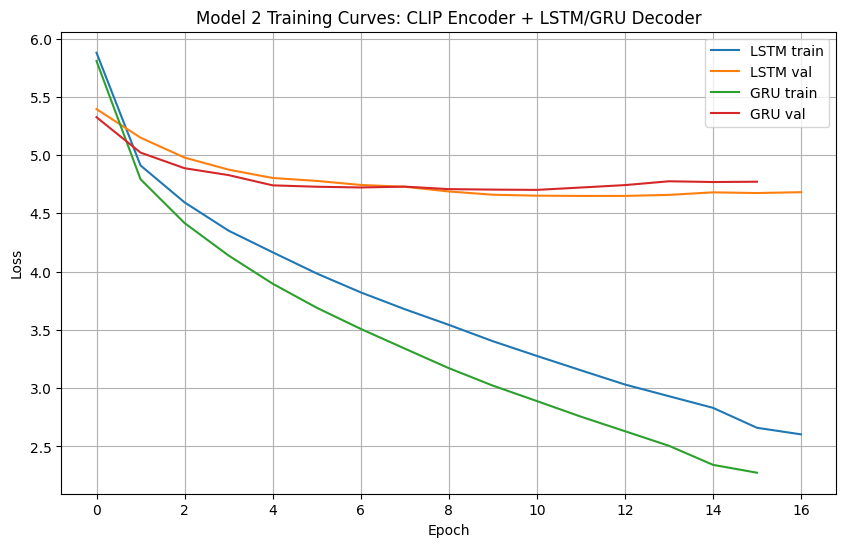

In [59]:
plt.figure(figsize=(10, 6))
for decoder_type, history in histories.items():
    plt.plot(history["train_loss"], label=f"{decoder_type.upper()} train")
    plt.plot(history["val_loss"], label=f"{decoder_type.upper()} val")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model 2 Training Curves: CLIP Encoder + LSTM/GRU Decoder")
plt.legend()
plt.grid(True)
plt.show()

## 20. Evaluation metrics: BLEU and ROUGE-L

BLEU and ROUGE are text generation metrics.

Important note: because our dataset is small and each image has only one target query, these metrics may be low even if some generated captions are visually reasonable. So we also inspect qualitative examples.

In [60]:
def lcs_length(x, y):
    # Longest Common Subsequence length
    m, n = len(x), len(y)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m):
        for j in range(n):
            if x[i] == y[j]:
                dp[i + 1][j + 1] = dp[i][j] + 1
            else:
                dp[i + 1][j + 1] = max(dp[i][j + 1], dp[i + 1][j])
    return dp[m][n]


def rouge_l_f1(reference_tokens, hypothesis_tokens):
    if len(reference_tokens) == 0 or len(hypothesis_tokens) == 0:
        return 0.0
    lcs = lcs_length(reference_tokens, hypothesis_tokens)
    precision = lcs / len(hypothesis_tokens)
    recall = lcs / len(reference_tokens)
    if precision + recall == 0:
        return 0.0
    return 2 * precision * recall / (precision + recall)


@torch.no_grad()
def evaluate_generation(decoder, dataset, max_samples=None):
    decoder.eval()
    references = []
    hypotheses = []
    rows = []

    indices = list(range(len(dataset)))
    if max_samples is not None:
        indices = indices[:max_samples]

    for idx in indices:
        image_tensor, _, gt_query, image_path = dataset[idx]
        pred = generate_caption_from_tensor(image_tensor, decoder, max_len=MAX_LEN)

        ref_tokens = tokenize(gt_query)
        hyp_tokens = tokenize(pred)

        references.append([ref_tokens])
        hypotheses.append(hyp_tokens)

        rows.append({
            "image_path": image_path,
            "ground_truth": gt_query,
            "prediction": pred,
            "rouge_l": rouge_l_f1(ref_tokens, hyp_tokens),
        })

    smoothie = SmoothingFunction().method4
    bleu1 = corpus_bleu(references, hypotheses, weights=(1, 0, 0, 0), smoothing_function=smoothie)
    bleu4 = corpus_bleu(references, hypotheses, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothie)
    avg_rouge_l = float(np.mean([r["rouge_l"] for r in rows])) if rows else 0.0

    return {
        "BLEU-1": bleu1 * 100,
        "BLEU-4": bleu4 * 100,
        "ROUGE-L": avg_rouge_l * 100,
        "examples": pd.DataFrame(rows),
    }

## 21. Compare LSTM and GRU quantitatively

This cell evaluates both trained decoders on the validation set.

In [61]:
metrics = {}
example_tables = {}

for decoder_type, decoder in trained_models.items():
    result = evaluate_generation(decoder, val_dataset)
    metrics[decoder_type] = {
        "model": decoder_type.upper(),
        "best_epoch": best_info[decoder_type]["best_epoch"],
        "best_val_loss": best_info[decoder_type]["best_val_loss"],
        "BLEU-1": result["BLEU-1"],
        "BLEU-4": result["BLEU-4"],
        "ROUGE-L": result["ROUGE-L"],
    }
    example_tables[decoder_type] = result["examples"]

comparison_df = pd.DataFrame(metrics.values())
comparison_df.to_csv(os.path.join(EXPORT_DIR, "model2_lstm_gru_comparison.csv"), index=False)
comparison_df

,model,best_epoch,best_val_loss,BLEU-1,BLEU-4,ROUGE-L
0,LSTM,12,4.649409,23.277910,2.448436,19.498842
1,GRU,11,4.701279,20.304017,3.288175,18.907561


## 22. Qualitative examples

This cell shows generated captions from both models for the same validation images.

In [62]:
num_examples = 8
sample_indices = random.sample(range(len(val_dataset)), min(num_examples, len(val_dataset)))

rows = []
for idx in sample_indices:
    image_tensor, _, gt_query, image_path = val_dataset[idx]
    row = {
        "image_path": image_path,
        "ground_truth": gt_query,
    }
    for decoder_type, decoder in trained_models.items():
        row[f"prediction_{decoder_type}"] = generate_caption_from_tensor(image_tensor, decoder, max_len=MAX_LEN)
    rows.append(row)

qual_df = pd.DataFrame(rows)
qual_df.to_csv(os.path.join(EXPORT_DIR, "model2_qualitative_examples.csv"), index=False)
qual_df

,image_path,ground_truth,prediction_lstm,prediction_gru
0,/content/drive/MyDrive/thumbnail_project/qvh_f...,Mother looking for teeth's in her baby's mouth,a woman is showing her outfit in the car,a woman in a white top is showing her outfit i...
1,/content/drive/MyDrive/thumbnail_project/qvh_f...,The mast of a sailboat is in view as the boat ...,a man in a black top is walking down the street,a man is pointing out a series of a city stree...
2,/content/drive/MyDrive/thumbnail_project/qvh_f...,Woman in pink dress vlogs in a restaurant kitc...,a woman is showing her outfit in the car,a woman is showing her daughter in the mirror
3,/content/drive/MyDrive/thumbnail_project/qvh_f...,Tourist showing his hotel room in Huston,a woman is showing her outfit in the car,a woman in a white top is showing her outfit i...
4,/content/drive/MyDrive/thumbnail_project/qvh_f...,Girls having some plain meal at restaurant sha...,a woman in a black top is showing her outfit i...,a woman in a white top is walking down the street
5,/content/drive/MyDrive/thumbnail_project/qvh_f...,Two young women walk down a Tokyo street toget...,a woman is showing her outfit in the car,a woman in a white top is walking down the street
6,/content/drive/MyDrive/thumbnail_project/qvh_f...,Two men walk through an airport to their gate.,a man in a black top is walking down the street,a man in a black t shirt is talking in front o...
7,/content/drive/MyDrive/thumbnail_project/qvh_f...,A female reporter in a blue sweatshirt is inte...,a man in a black top is walking down the street,man in blue shirt is talking in front of a camera


## 23. Visual qualitative grid

This grid is useful for your presentation/report because it shows:

- the input frame
- the ground-truth query
- the LSTM prediction
- the GRU prediction

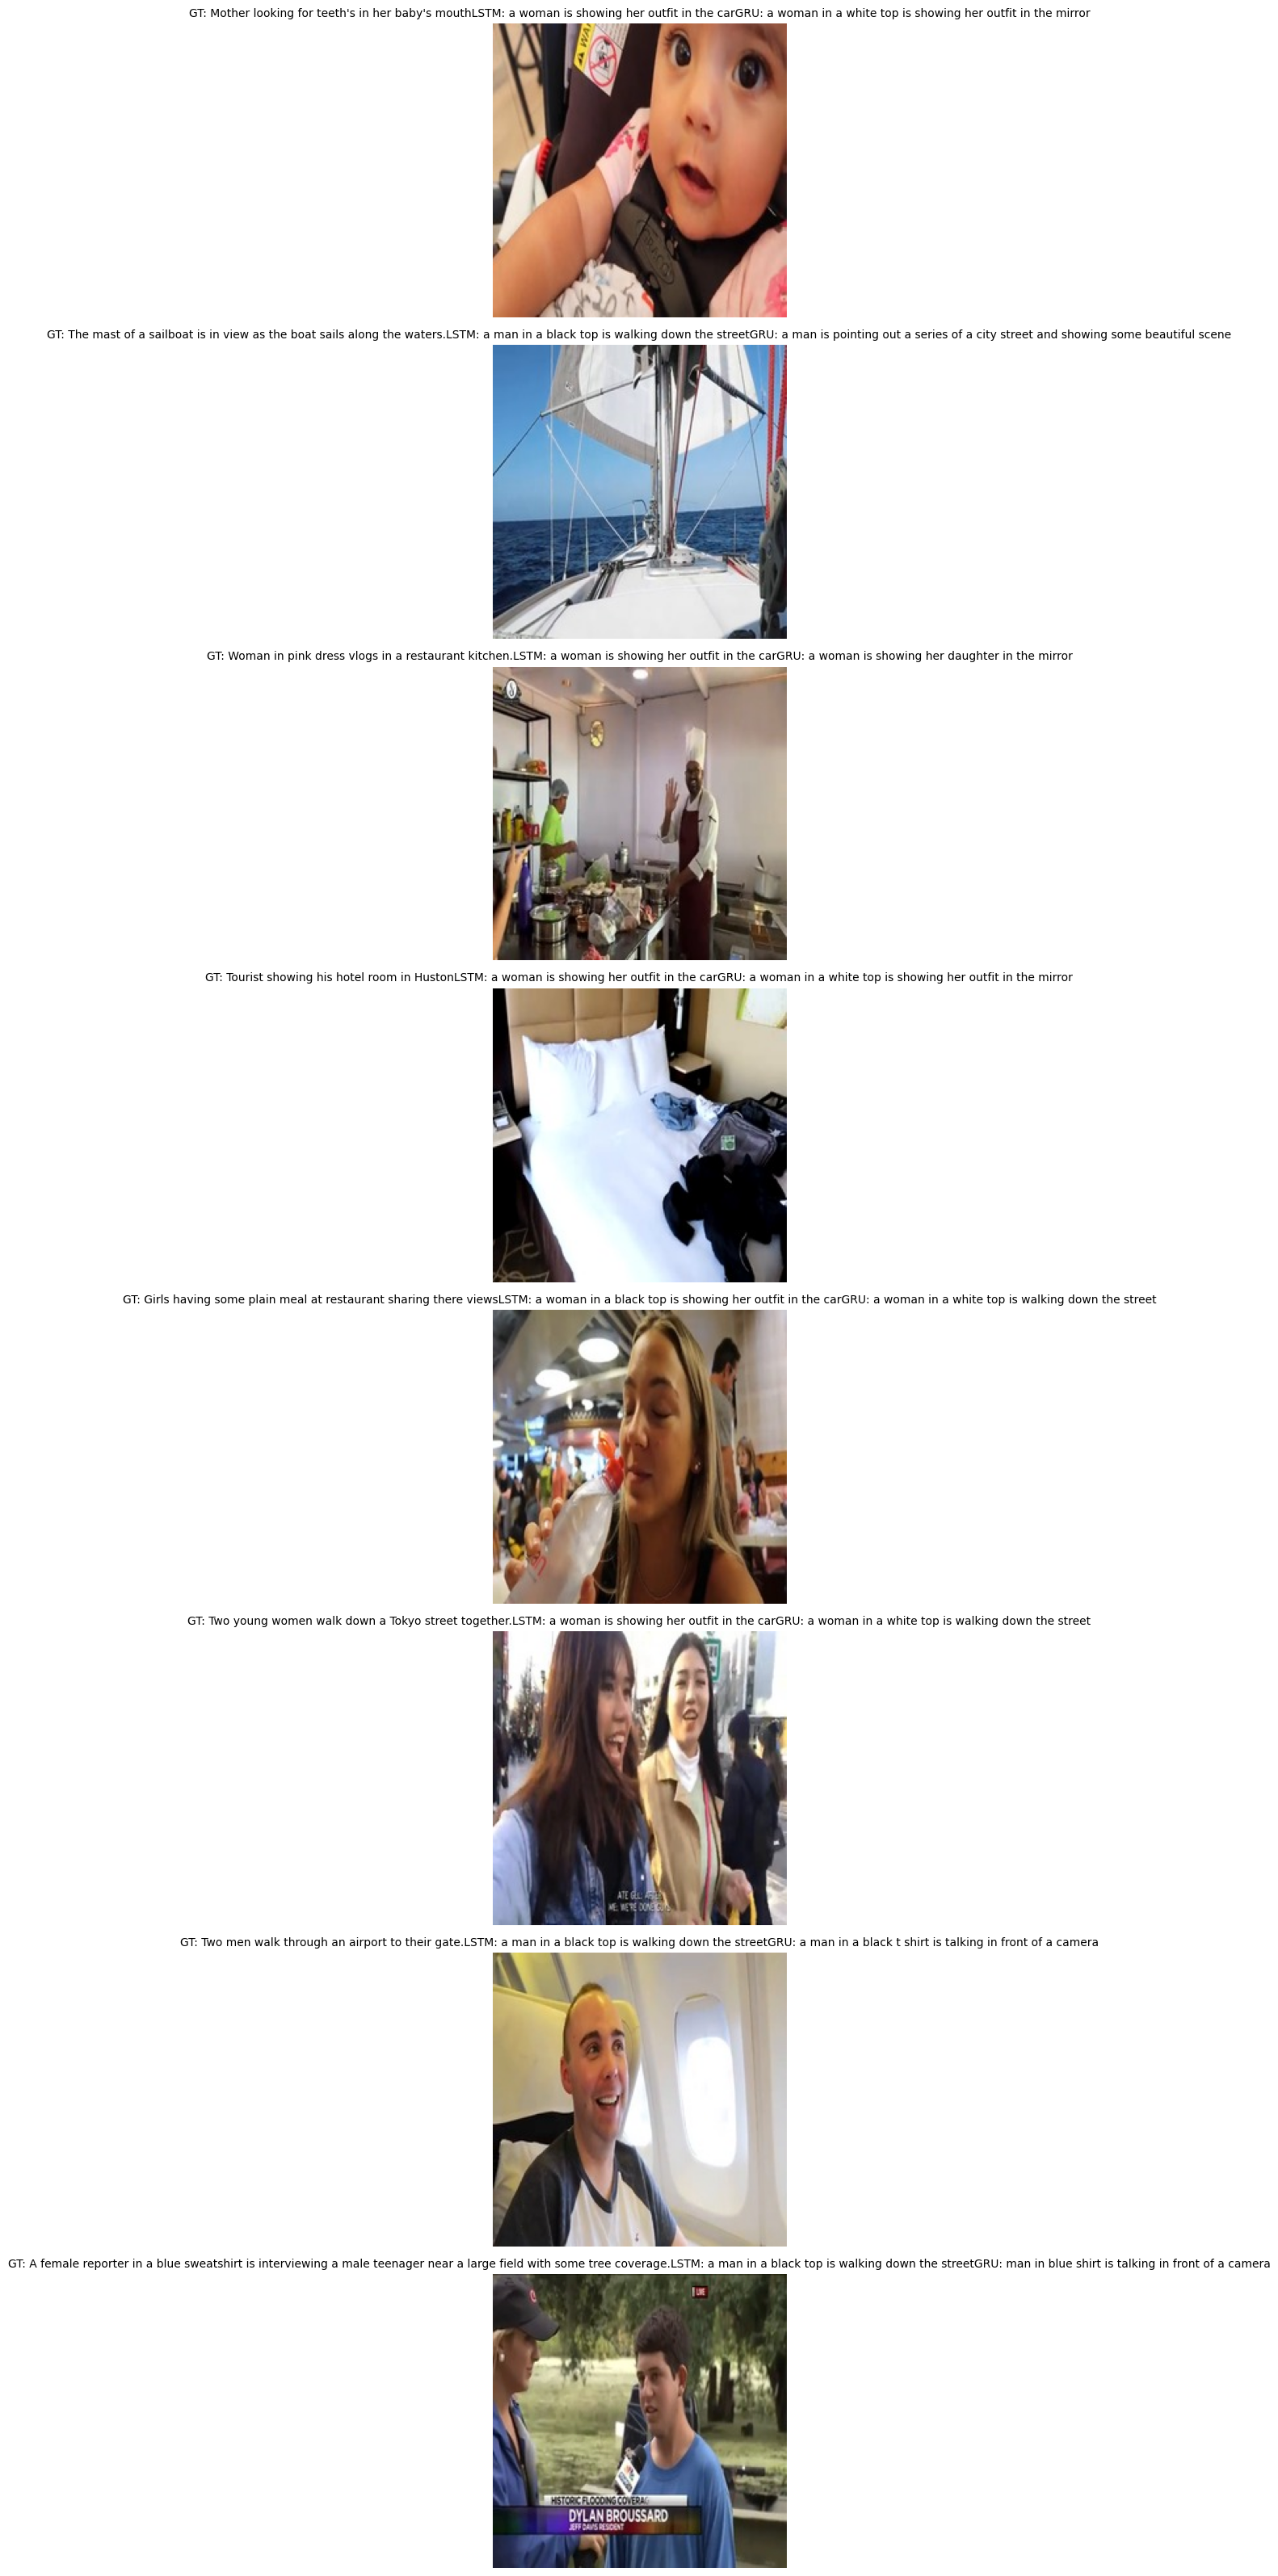

In [67]:
plt.figure(figsize=(16, 4 * len(rows)))
for i, row in enumerate(rows):
    image = Image.open(row["image_path"]).convert("RGB")
    plt.subplot(len(rows), 1, i + 1)
    plt.imshow(image)
    plt.axis("off")
    title = (f"GT: {row['ground_truth']}" f"LSTM: {row.get('prediction_lstm', '')}"f"GRU: {row.get('prediction_gru', '')}")
    plt.title(title, fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, "model2_qualitative_grid.png"), dpi=150, bbox_inches="tight")
plt.show()

## 24. Test on any single image

Use this cell to generate text for any frame or future thumbnail.

For future thumbnails, use the same preprocessing pipeline so the input distribution stays consistent.

Image: /content/drive/MyDrive/thumbnail_project/qvh_frames/t_9gaLdfc_Y_210.0_360.0.jpg
Generated caption: a man in a black top is walking down the street


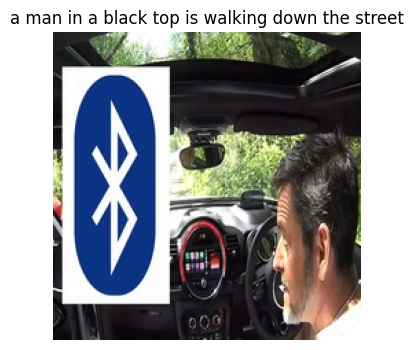

In [65]:
# Change this to any image path you want to test.
TEST_IMAGE_PATH = val_pairs[0]["frame_path"]

# Choose best model manually after checking the comparison table.
BEST_DECODER_TYPE = "lstm"  # change to "gru" if GRU performs better
best_decoder = trained_models[BEST_DECODER_TYPE]

pred_caption = generate_caption_from_path(TEST_IMAGE_PATH, best_decoder)
print("Image:", TEST_IMAGE_PATH)
print("Generated caption:", pred_caption)

plt.figure(figsize=(6, 4))
plt.imshow(Image.open(TEST_IMAGE_PATH).convert("RGB"))
plt.axis("off")
plt.title(pred_caption)
plt.show()

## 25. Save final metadata

This saves important settings so you can explain the model and reload it later.

In [66]:
metadata = {
    "project": "ANNs Project - Model 2",
    "model": "Frozen CLIP image encoder + LSTM/GRU decoder",
    "clip_model_name": CLIP_MODEL_NAME,
    "max_caption_length": MAX_LEN,
    "vocab_size": VOCAB_SIZE,
    "train_pairs": len(train_pairs),
    "val_pairs": len(val_pairs),
    "batch_size": BATCH_SIZE,
    "epochs_requested": EPOCHS,
    "patience": PATIENCE,
    "learning_rate": LR,
    "weight_decay": WEIGHT_DECAY,
    "embed_dim": EMBED_DIM,
    "hidden_dim": HIDDEN_DIM,
    "dropout": DROPOUT,
    "best_info": best_info,
    "best_paths": best_paths,
}

with open(os.path.join(EXPORT_DIR, "model2_metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved metadata to:", os.path.join(EXPORT_DIR, "model2_metadata.json"))
print("Saved comparison CSV to:", os.path.join(EXPORT_DIR, "model2_lstm_gru_comparison.csv"))
print("Saved qualitative examples CSV to:", os.path.join(EXPORT_DIR, "model2_qualitative_examples.csv"))

Saved metadata to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru/model2_metadata.json
Saved comparison CSV to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru/model2_lstm_gru_comparison.csv
Saved qualitative examples CSV to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_lstm_gru/model2_qualitative_examples.csv


## 26. Draft conclusion template

After running the notebook, fill this based on your actual values.

```text
In Model 2, we replaced the previous CLIP + GPT-2 approach with a Frozen CLIP Encoder + RNN Decoder architecture. CLIP was used only for image feature extraction, while the generated text was produced by trainable LSTM and GRU decoders. This kept the model closer to the ANN course topics and avoided the long story-like outputs caused by GPT-2.

Because the dataset was small, we used early stopping, dropout, light image augmentation, a frozen encoder, and a limited caption length of 25 tokens. These choices helped reduce overfitting.

The LSTM decoder achieved validation loss = ___, BLEU-4 = ___, and ROUGE-L = ___.
The GRU decoder achieved validation loss = ___, BLEU-4 = ___, and ROUGE-L = ___.

Based on the results, the better decoder was ___ because ___.

For the next step, we should adapt Model 2 to real thumbnails by manually annotating a small thumbnail dataset and fine-tuning the decoder, because the final app will receive real thumbnails rather than only best frames.
```